### 1. Import Libraries

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt    
import seaborn as sns


### 2. Load the Dataset

In [3]:
#read the dataset

df = pd.read_csv('../data/mobile_price.csv')
print(df.shape)

(2000, 21)


### 3.Preview and Inspect the Data

In [4]:
# 1. Understand the dataset
print("First five rows:")
display(df.head())

First five rows:


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7.0,0.6,188,2,...,20,756.0,2549.0,9,7,19,0.0,0,1,1
1,1021,1,0.5,1,0,1,53.0,0.7,136,3,...,905,1988.0,2631.0,17,3,7,1.0,1,0,2
2,563,1,0.5,1,2,1,41.0,0.9,145,5,...,1263,1716.0,2603.0,11,2,9,1.0,1,0,2
3,615,1,2.5,0,0,0,10.0,0.8,131,6,...,1216,1786.0,2769.0,16,8,11,1.0,0,0,2
4,1821,1,1.2,0,13,1,44.0,0.6,141,2,...,1208,1212.0,1411.0,8,2,15,1.0,1,0,1


In [5]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     1999 non-null   float64
 7   m_dep          1999 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       1999 non-null   float64
 13  ram            1999 non-null   float64
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        1999 non-null   float64
 1

In [6]:
print("\nDataset shape (rows, columns):")
print(df.shape)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())


Dataset shape (rows, columns):
(2000, 21)

Missing values in each column:
battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       1
m_dep            1
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         1
ram              1
sc_h             0
sc_w             0
talk_time        0
three_g          1
touch_screen     0
wifi             0
price_range      0
dtype: int64

Number of duplicate rows:
0


In [7]:
print("\nStatistical summary:")
print(df.describe())


Statistical summary:
       battery_power       blue  clock_speed     dual_sim           fc  \
count    2000.000000  2000.0000  2000.000000  2000.000000  2000.000000   
mean     1238.518500     0.4950     1.522250     0.509500     4.309500   
std       439.418206     0.5001     0.816004     0.500035     4.341444   
min       501.000000     0.0000     0.500000     0.000000     0.000000   
25%       851.750000     0.0000     0.700000     0.000000     1.000000   
50%      1226.000000     0.0000     1.500000     1.000000     3.000000   
75%      1615.250000     1.0000     2.200000     1.000000     7.000000   
max      1998.000000     1.0000     3.000000     1.000000    19.000000   

            four_g   int_memory        m_dep    mobile_wt      n_cores  ...  \
count  2000.000000  1999.000000  1999.000000  2000.000000  2000.000000  ...   
mean      0.521500    32.035018     0.501601   140.249000     4.520500  ...   
std       0.499662    18.142986     0.288411    35.399655     2.287837  ..

### 4. Count Phones in Each Price Category


Number of phones in each price category:
price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64


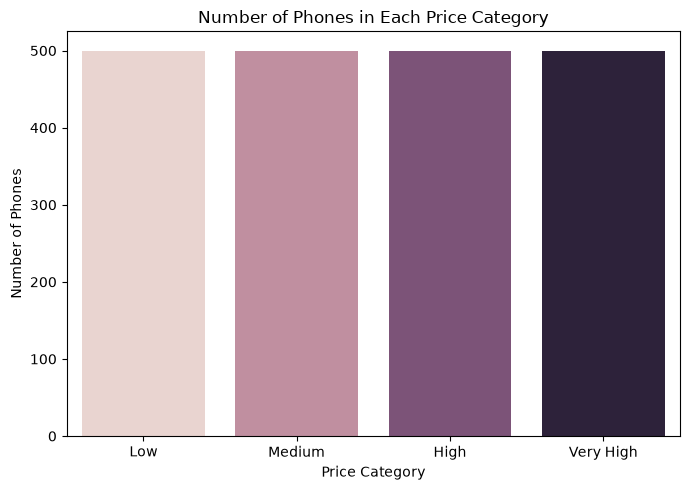

In [28]:
# 2. Understand the target variable
price_labels = ["Low", "Medium", "High", "Very High"]
print("\nNumber of phones in each price category:")
print(df["price_range"].value_counts().sort_index())

# 3. Plot the number of phones in each category
plt.figure(figsize=(7, 5))
sns.countplot(x="price_range", hue="price_range", data=df, legend=False)
plt.title("Number of Phones in Each Price Category")
plt.xlabel("Price Category")
plt.ylabel("Number of Phones")
plt.xticks([0, 1, 2, 3], ["Low", "Medium", "High", "Very High"])
plt.tight_layout()
plt.show()

### 5. Plot the Distribution of RAM

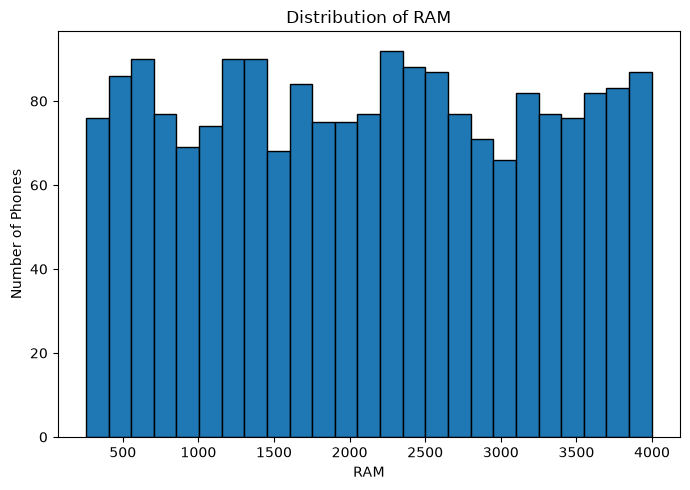

In [30]:
# 4. Plot the distribution of RAM
plt.figure(figsize=(7, 5))
plt.hist(df["ram"].dropna(), bins=25, edgecolor="black")   #excluding the missing values
plt.title("Distribution of RAM")
plt.xlabel("RAM")
plt.ylabel("Number of Phones")
plt.tight_layout()
plt.show()

### 6. Compare RAM Across Price Categories

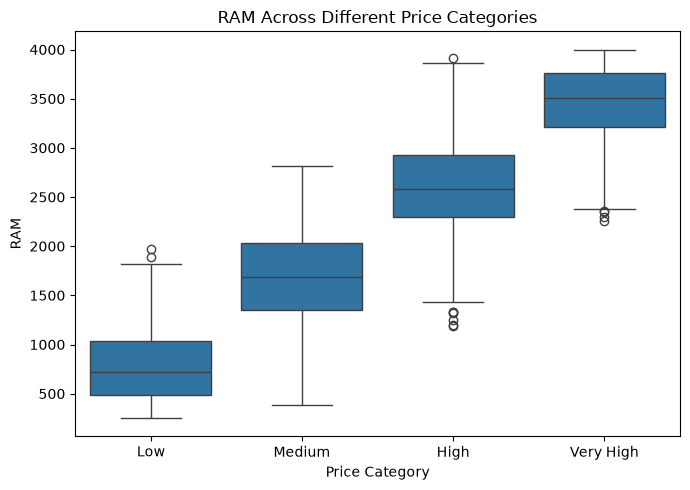

In [31]:
# 5. Compare RAM with price category
plt.figure(figsize=(7, 5))
sns.boxplot(x="price_range", y="ram", data=df)
plt.title("RAM Across Different Price Categories")
plt.xlabel("Price Category")
plt.ylabel("RAM")
plt.xticks([0, 1, 2, 3], ["Low", "Medium", "High", "Very High"])
plt.tight_layout()
plt.show()

### 7. Plot the Correlation Heatmap

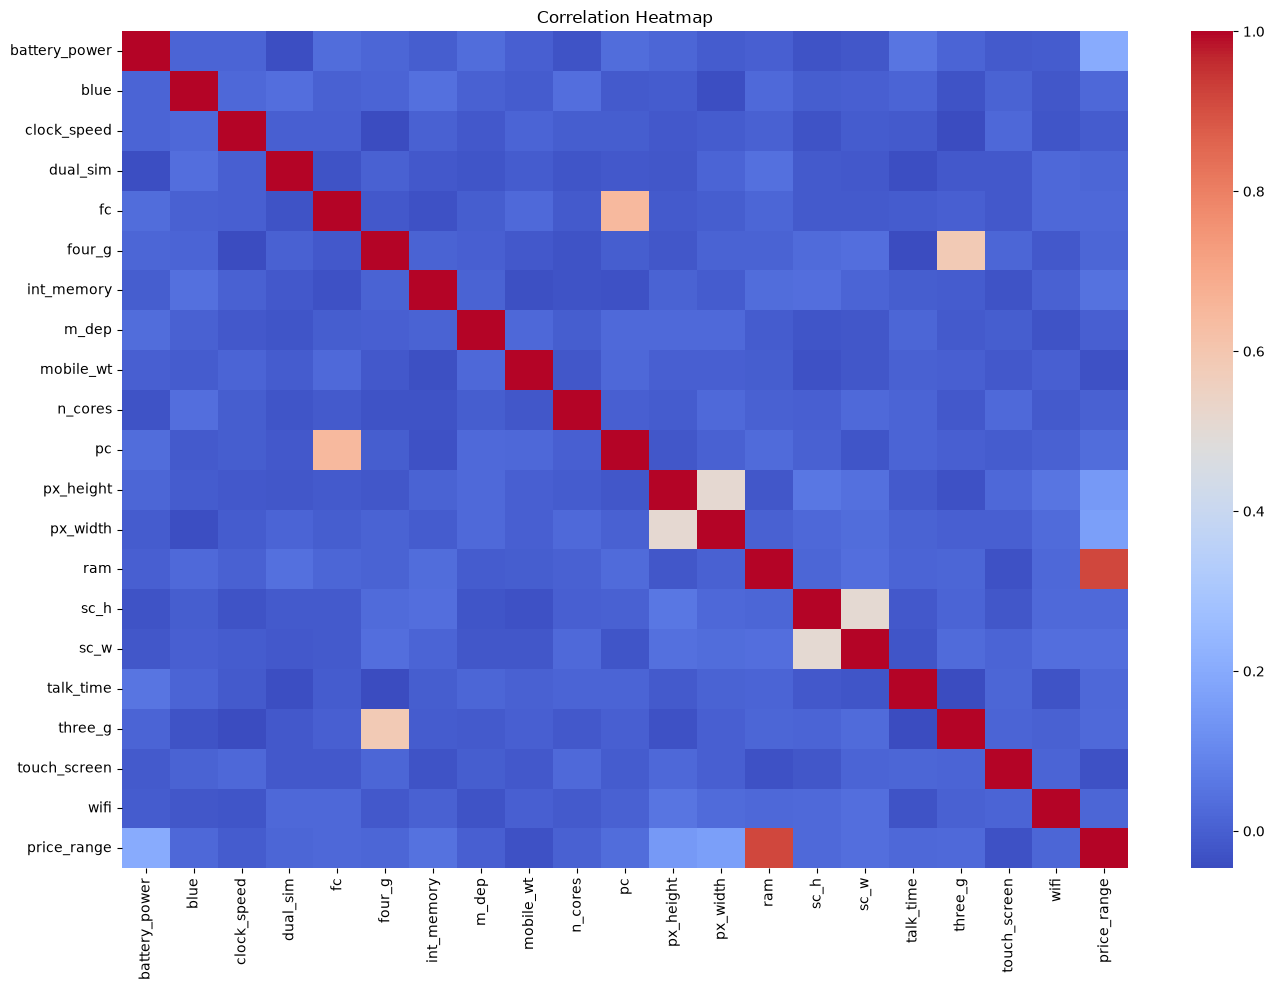

In [33]:

# 6. Correlation between numerical columns
orrelation_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), cmap="coolwarm", annot=False)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()
